# ファクターリターンの時系列特性

これまでの実験は「どのファクターが横断面で効くか」を見てきた。ここでは視点を変えて、**ファクターのロングショート・リターン自体を時系列として**見る。
問いは一つ: **ファクターの過去の成績・ボラ・割安度（バリュエーション）といった時系列情報で、`comp_ew` の重み付けを動かす余地はあるか。**

**仮説と予測**

| 仮説 | 文献 | 予測（仮説が正しければ見えるはず） |
| --- | --- | --- |
| H1 ファクターモメンタム | Ehsani–Linnainmaa (2022), Gupta–Kelly (2019) | ファクターリターンは正の自己相関を持ち、過去 12 か月が正のファクターだけ持つ合成が静的な等ウェイト合成を上回る |
| H2 ボラ・タイミング | Moreira–Muir (2017) | 前月の実現分散で割り戻したファクターは、元のファクターに対して正のアルファを持つ（特にモメンタム） |
| H3 ファクターの割安度 | Asness et al. (2000), Arnott et al. (2016) | ロング側がショート側より（自身の過去と比べて）割安なとき、ファクターの翌期リターンが高い |
| H4 市場との非対称 | Daniel–Moskowitz (2016) | モメンタム系は下落市場で勝ち、急反発月に負ける（下方ベータ ≠ 上方ベータ） |

既存の実験との関係: `style_dtw` はスタイル 9 本の予測（DTW、12 か月・3 か月モメンタム）を**銘柄スコアに写した形**で試し、上乗せが無かった。
`momentum_regime` は弱気局面でのモメンタム外しを試した。ここではもっと素朴に、**ファクター 130 本のリターン系列そのもの**の性質を一通り測る。

**設計**

- ファクター: `core` 123 本（`mv` などの属性も含む）、`composite/comp_ew` とスリーブ `sleeve_a/b/d`、スタイル 9 本（`build_style_dtw.build_style_scores`、向き調整済み）
- 月次ロングショート: 月末 $t$ のユニバース内でパーセンタイル $p=(\mathrm{rank}-0.5)/N$、$Q5=\{p\ge0.8\}$、$Q1=\{p<0.2\}$（スコアの素の向き）。
  翌月の `drtn`（配当込み）を等ウェイトで平均し $f_{t+1}=\bar r_{Q5}-\bar r_{Q1}$。スコアのある銘柄が 50 未満の月は欠損
- 日次ロングショート: 同じ $Q5/Q1$ を翌月の各営業日に固定し、日次の価格リターンで等ウェイト平均（実現分散用）
- 向き: 記述統計では全期間平均の符号で揃える（以下「向き調整後」）。**戦略として評価する合成では、$t$ までの拡大窓平均の符号だけを使う**（最低 24 か月、合成の評価は 2010-02 以降）
- t 値は Newey–West（月次は既定でラグ 3、12 か月重複リターンはラグ 12）。IS = 2008〜2017、OOS = 2018〜

**規約**: 期間はスコア月 2007-12〜2026-06（リターン月 2008-01〜2026-07）。ユニバースは MSCI India IMI プロキシ（`univ`）。リターンはリターン月で表示する。

In [1]:
import sys
import warnings
from pathlib import Path

import japanize_matplotlib  # noqa: F401  日本語ラベル用
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../../scripts").resolve()))
from build_market_panel import daily_membership, load_panel
from build_style_dtw import build_style_scores

from alphaeval import InputStore

warnings.simplefilter("ignore", RuntimeWarning)
pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

INPUT_ROOT = "../../input/msci_india_imi"
START, END = 200712, 202606  # スコア月
IS_END = pd.Timestamp("2017-12-31")
EVAL_START = pd.Timestamp("2010-02-28")  # 拡大窓の向き（24 か月）が揃う月
TOP, BOTTOM = 0.8, 0.2
MIN_STOCKS = 50
MIN_DAYS = 10

store = InputStore(INPUT_ROOT)
panel = load_panel("../../data/market_panel", fields=("ret",))
univ_w = store.universe(START, END)
MONTHS = univ_w.index
COLS = univ_w.columns
univ = univ_w.notna()

drtn = panel.monthly["drtn"]
fwd = drtn.shift(-1).reindex(index=MONTHS, columns=COLS)  # 行 t = 月 t+1 のリターン
pbr = panel.monthly["pbr"]
bp = (1.0 / pbr.where((pbr > 0) & (pbr <= 1000))).reindex(
    index=MONTHS, columns=COLS
)  # -1e9 のセンチネルと極端値は除外
ret_d = panel.daily["ret"].loc["2008-01-01":].reindex(columns=COLS)
DAYS = ret_d.index
mkt = panel.monthly_index
cw = mkt["cw_imi"].rename("CW")
ew_cw = (mkt["ew_imi"] - mkt["cw_imi"]).rename("EW−CW")
print(univ.sum(axis=1).describe().round(0).to_dict())

{'count': 223.0, 'mean': 374.0, 'std': 133.0, 'min': 211.0, '25%': 290.0, '50%': 331.0, '75%': 397.0, 'max': 683.0}


In [2]:
def nw_se(x: np.ndarray, lags: int) -> float:
    """平均の Newey–West 標準誤差。"""
    n = len(x)
    e = x - x.mean()
    s = e @ e / n
    for lag in range(1, lags + 1):
        s += 2 * (1 - lag / (lags + 1)) * (e[lag:] @ e[:-lag]) / n
    return np.sqrt(s / n)


def nw_t(x: pd.Series, lags: int = 3) -> float:
    """平均の Newey–West t 値。"""
    v = pd.Series(x).dropna().to_numpy()
    return v.mean() / nw_se(v, lags) if len(v) > lags + 2 else np.nan


def ols_nw(y: pd.Series, X: pd.DataFrame, lags: int = 3) -> pd.DataFrame:
    """OLS の係数と Newey–West t 値。"""
    df = pd.concat([y.rename("_y"), X], axis=1).dropna()
    yv = df["_y"].to_numpy()
    Xv = np.column_stack([np.ones(len(df)), df.drop(columns="_y").to_numpy()])
    b = np.linalg.lstsq(Xv, yv, rcond=None)[0]
    u = yv - Xv @ b
    Xu = Xv * u[:, None]
    S = Xu.T @ Xu
    for lag in range(1, lags + 1):
        G = Xu[lag:].T @ Xu[:-lag]
        S += (1 - lag / (lags + 1)) * (G + G.T)
    XtXi = np.linalg.inv(Xv.T @ Xv)
    V = XtXi @ S @ XtXi
    out = pd.DataFrame(
        {"coef": b, "t": b / np.sqrt(np.diag(V))},
        index=["const", *df.columns.drop("_y")],
    )
    out.attrs["n"] = len(df)
    return out


def perf(x: pd.Series, lags: int = 3) -> dict:
    """年率平均・ボラ・シャープ・NW t 値。"""
    x = x.dropna()
    return {
        "年率": x.mean() * 12,
        "ボラ": x.std() * np.sqrt(12),
        "シャープ": x.mean() / x.std() * np.sqrt(12),
        "t": nw_t(x, lags),
        "月数": len(x),
    }


def perf_split(x: pd.Series) -> dict:
    """全期間・IS・OOS の年率と t 値。"""
    x = x.dropna()
    a, i, o = (
        perf(x),
        perf(x.loc[:IS_END]),
        perf(x.loc[IS_END + pd.Timedelta(days=1) :]),
    )
    return {
        "年率": a["年率"], "t": a["t"], "シャープ": a["シャープ"],
        "IS 年率": i["年率"], "IS t": i["t"], "OOS 年率": o["年率"], "OOS t": o["t"],
    }  # fmt: skip


def max_dd(x: pd.Series) -> float:
    """単利累積（ロングショート）の最大ドローダウン。"""
    c = x.fillna(0).cumsum()
    return (c - c.cummax()).min()


def quantile_masks(score: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """月末ユニバース内の Q5 / Q1 の真偽値。"""
    s = score.reindex(index=MONTHS, columns=COLS).where(univ)
    n = s.notna().sum(axis=1)
    p = s.rank(axis=1).sub(0.5).div(n, axis=0)
    ok = (n >= MIN_STOCKS).to_numpy()[:, None]
    return (p >= TOP) & ok, (p < BOTTOM) & ok


def to_return_month(s: pd.Series) -> pd.Series:
    """スコア月 t の値をリターン月 t+1 のラベルに付け替える。"""
    s = s.copy()
    s.index = s.index + pd.offsets.MonthEnd(1)
    return s


def factor_series(score: pd.DataFrame) -> dict[str, pd.Series]:
    """月次 Q5−Q1、Q5−ユニバース EW、日次 Q5−Q1、BP スプレッド（スコア月）。"""
    top, bot = quantile_masks(score)
    ok = top.any(axis=1)
    r5, r1, ru = (
        fwd.where(top).mean(axis=1),
        fwd.where(bot).mean(axis=1),
        fwd.where(univ).mean(axis=1),
    )
    td = daily_membership(top.astype(float).where(top), DAYS).notna()
    bd = daily_membership(bot.astype(float).where(bot), DAYS).notna()
    d = ret_d.where(td).mean(axis=1) - ret_d.where(bd).mean(axis=1)
    vs = np.log(bp.where(top).median(axis=1) / bp.where(bot).median(axis=1))
    return {
        "ls": to_return_month((r5 - r1).where(ok)),
        "q5x": to_return_month((r5 - ru).where(ok)),
        "daily": d.where(td.any(axis=1)),
        "vs": vs.where(ok),
    }

## 1. ファクターリターンのパネル

`core` 123 本、`comp_ew` とスリーブ、スタイル 9 本の月次ロングショートを作る。スタイルは `style_dtw/output/style_daily_returns.csv`（日次、価格リターン）を
月次に複利集計したものとの相関で作り方を照合する。

In [3]:
core_names = sorted(
    a.split("/", 1)[1] for a in store.list_alphas() if a.startswith("core/")
)
comp_names = ["comp_ew", "sleeve_a", "sleeve_b", "sleeve_d"]
series: dict[str, dict[str, pd.Series]] = {}
for n in core_names:
    series[n] = factor_series(store.alpha(f"core/{n}", START, END))
for n in comp_names:
    series[n] = factor_series(store.alpha(f"composite/{n}", START, END))
sscores = build_style_scores(store, univ_w)
STYLES = list(sscores)
for n in STYLES:
    series[n] = factor_series(sscores[n])
del sscores

F = pd.DataFrame({n: s["ls"] for n, s in series.items()})  # リターン月 × ファクター
Q5X = pd.DataFrame({n: s["q5x"] for n, s in series.items()})
D = pd.DataFrame({n: s["daily"] for n, s in series.items()})
VS = pd.DataFrame({n: s["vs"] for n, s in series.items()})  # スコア月
del series
F = F.loc["2008-01-31":"2026-07-31"]
Q5X = Q5X.loc[F.index]
print(
    "ファクター数",
    F.shape[1],
    "月数",
    len(F),
    "欠損率",
    round(F.isna().mean().mean(), 3),
)
print("月の数が 120 未満のファクター:", F.count()[F.count() < 120].to_dict())

csv = pd.read_csv(
    "../style_dtw/output/style_daily_returns.csv", index_col=0, parse_dates=True
)
csv_m = (1 + csv).groupby(csv.index.to_period("M")).prod() - 1
csv_m.index = csv_m.index.to_timestamp(how="end").normalize()
chk = pd.DataFrame(
    {s: F[s].corr(csv_m[s]) for s in STYLES},
    index=["相関（月次 drtn vs CSV 日次の複利）"],
).T
display(chk.round(3).T)

ファクター数 136 月数 223 欠損率 0.029
月の数が 120 未満のファクター: {'availm12': 0, 'availm60': 0, 'buyback': 49, 'intwo': 0}


,Stock Value,Flow Value,Profitability,Growth,Shareholder Return,Momentum,Volatility,Financial Quality,Size
相関（月次 drtn vs CSV 日次の複利）,0.991,0.986,0.981,0.98,0.971,0.983,0.973,0.979,0.964


## 2. 基本統計

### 2.1 スタイルと合成スコア

累積（単利の和、対数ではなく累積ロングショート）とドローダウン。向き調整は不要（いずれも高いほど良い向き）。

,年率,ボラ,シャープ,t,月数,最大DD,Q5−EW 年率
comp_ew,0.179,0.162,1.099,5.158,222.0,-0.388,0.098
sleeve_a,0.141,0.106,1.327,5.793,222.0,-0.216,0.086
sleeve_b,0.088,0.185,0.473,2.058,222.0,-0.642,0.052
sleeve_d,0.119,0.106,1.122,4.415,222.0,-0.216,0.041
Stock Value,0.028,0.214,0.130,0.553,223.0,-1.117,0.006
Flow Value,0.108,0.146,0.742,2.823,223.0,-0.572,0.028
Profitability,0.027,0.175,0.157,0.705,223.0,-0.749,0.003
Growth,-0.053,0.108,-0.494,-1.694,223.0,-1.171,-0.045
Shareholder Return,0.111,0.130,0.854,3.562,223.0,-0.220,0.047
Momentum,0.113,0.183,0.616,2.673,223.0,-0.633,0.065


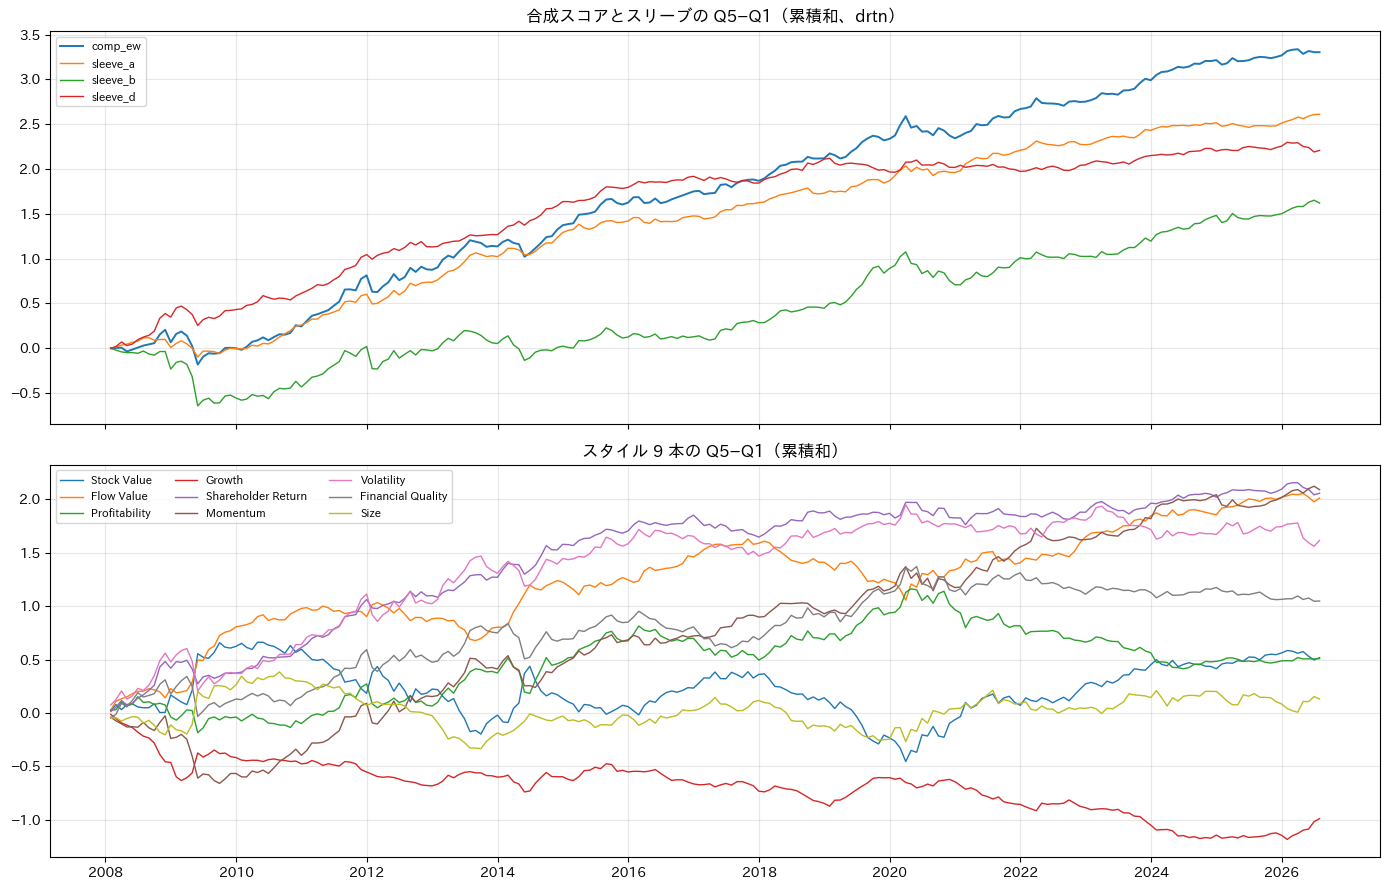

In [4]:
key = ["comp_ew", "sleeve_a", "sleeve_b", "sleeve_d", *STYLES]
tbl = pd.DataFrame(
    {
        n: {**perf(F[n]), "最大DD": max_dd(F[n]), "Q5−EW 年率": Q5X[n].mean() * 12}
        for n in key
    }
).T
display(tbl.round(3))

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
for n in ["comp_ew", "sleeve_a", "sleeve_b", "sleeve_d"]:
    axes[0].plot(
        F[n].fillna(0).cumsum(), label=n, linewidth=1.4 if n == "comp_ew" else 1
    )
axes[0].set_title("合成スコアとスリーブの Q5−Q1（累積和、drtn）")
axes[0].legend(fontsize=8)
for i, n in enumerate(STYLES):
    axes[1].plot(F[n].fillna(0).cumsum(), label=n, linewidth=1, color=f"C{i}")
axes[1].set_title("スタイル 9 本の Q5−Q1（累積和）")
axes[1].legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

### 2.2 `core` 123 本の分布

全期間平均の符号で向きを揃えた後の t 値の分布と上位・下位。向きは結果を見て決めているので、**ここでの t 値の大きさは楽観的**（記述用）。

向き調整後の t 値: |t|>2 の本数 35 / 123   OOS でも t>2: 7   IS の符号が OOS で反転: 37


,年率,t,シャープ,IS 年率,IS t,OOS 年率,OOS t,向き,最大DD
dp_act,0.129,5.016,1.363,0.185,5.075,0.064,1.951,1.0,-0.120
rev3r,0.151,4.754,1.073,0.162,3.185,0.138,3.966,1.0,-0.318
xfin_sp,0.098,4.716,1.131,0.130,4.291,0.061,2.324,-1.0,-0.160
rev1r,0.117,4.685,1.099,0.116,2.932,0.118,4.192,1.0,-0.273
noa_grw_fy,0.102,4.525,1.131,0.137,4.060,0.061,2.273,-1.0,-0.179
rev3p,0.147,4.220,0.961,0.166,2.923,0.125,3.451,1.0,-0.368
rev1p,0.113,4.145,0.993,0.111,2.530,0.116,3.882,1.0,-0.323
dp_est,0.105,3.775,1.047,0.155,3.825,0.047,1.361,1.0,-0.199
xfin_bs,0.102,3.759,0.809,0.161,3.849,0.033,1.230,-1.0,-0.250
diss,0.068,3.699,0.796,0.115,4.446,0.014,0.630,1.0,-0.248


,年率,t,シャープ,IS 年率,IS t,OOS 年率,OOS t,向き,最大DD
mv_usd,0.003,0.082,0.018,0.005,0.086,0.001,0.021,1.0,-0.613
mv,0.003,0.082,0.018,0.005,0.086,0.001,0.021,1.0,-0.613
eq_tl,0.003,0.079,0.019,0.039,0.716,-0.039,-0.823,-1.0,-0.776
roa_est,0.003,0.076,0.016,-0.019,-0.340,0.028,0.748,-1.0,-0.691
tl_ta,0.003,0.073,0.017,0.033,0.618,-0.033,-0.703,1.0,-0.741
eqr,0.001,0.022,0.005,-0.031,-0.575,0.038,0.786,1.0,-0.609
peg_est,0.000,0.013,0.003,-0.001,-0.017,0.002,0.042,1.0,-0.705
availm12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000
availm60,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000
intwo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000


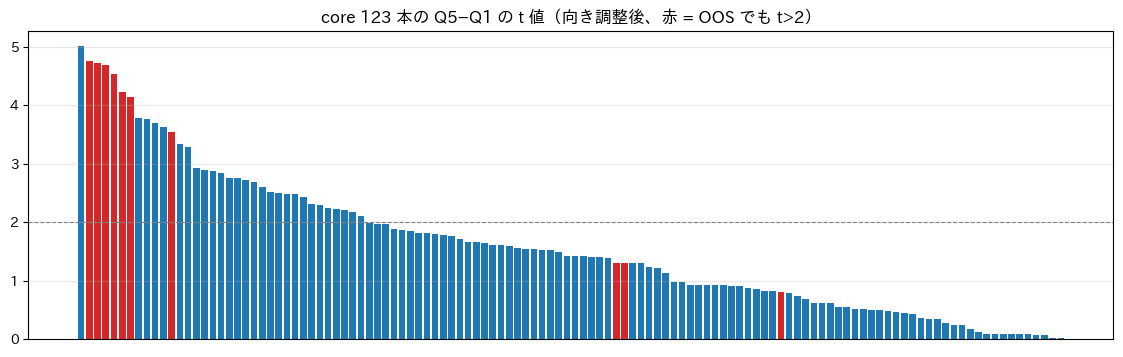

In [5]:
dir_full = np.sign(F.mean())
G_full = F * dir_full
core_tbl = pd.DataFrame(
    {
        n: {**perf_split(G_full[n]), "向き": dir_full[n], "最大DD": max_dd(G_full[n])}
        for n in core_names
    }
).T
core_tbl = core_tbl.sort_values("t", ascending=False)
print(
    "向き調整後の t 値: |t|>2 の本数",
    int((core_tbl["t"] > 2).sum()),
    "/",
    len(core_tbl),
    "  OOS でも t>2:",
    int(((core_tbl["t"] > 2) & (core_tbl["OOS t"] > 2)).sum()),
    "  IS の符号が OOS で反転:",
    int((np.sign(core_tbl["IS 年率"]) != np.sign(core_tbl["OOS 年率"])).sum()),
)
display(core_tbl.head(15).round(3))
display(core_tbl.tail(10).round(3))

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(
    range(len(core_tbl)),
    core_tbl["t"],
    color=np.where(core_tbl["OOS t"] > 2, "C3", "C0"),
)
ax.axhline(2, color="gray", linestyle="--", linewidth=0.8)
ax.set_title("core 123 本の Q5−Q1 の t 値（向き調整後、赤 = OOS でも t>2）")
ax.set_xticks([])
plt.show()

### 2.3 ファクター間の相関構造

`core` 123 本（向き調整後）の相関行列の固有値。第 1 主成分の説明力を 36 か月の移動窓でも見る（ファクターが「一つの賭け」になっている度合いの時系列）。

使ったファクター 119 本。固有値の説明力: PC1 41.0%, PC1–3 57.8%, PC1–5 65.2%, PC1–10 76.3%
PC1 の負荷量 上位: {'gpa_act_fy': 0.13, 'roe_act': 0.13, 'roic_act': 0.13, 'ocftd': 0.13, 'pti_tl': 0.13, 'roe_est': 0.13, 'ni_ta': 0.13, 'ocf_ta': 0.13}
PC1 の負荷量 下位: {'mve_tl': -0.14, 'tobin_q': -0.14, 'zscore': -0.14, 'bp_est': -0.13, 'bp_act': -0.13, 'sp_act': -0.13, 'cfp_est': -0.12, 'peg_est': -0.12}


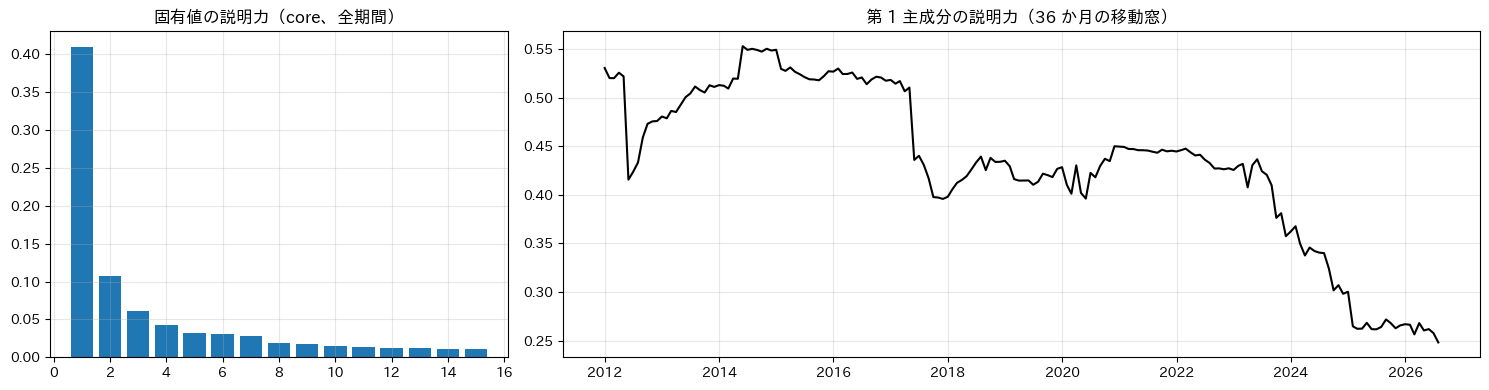

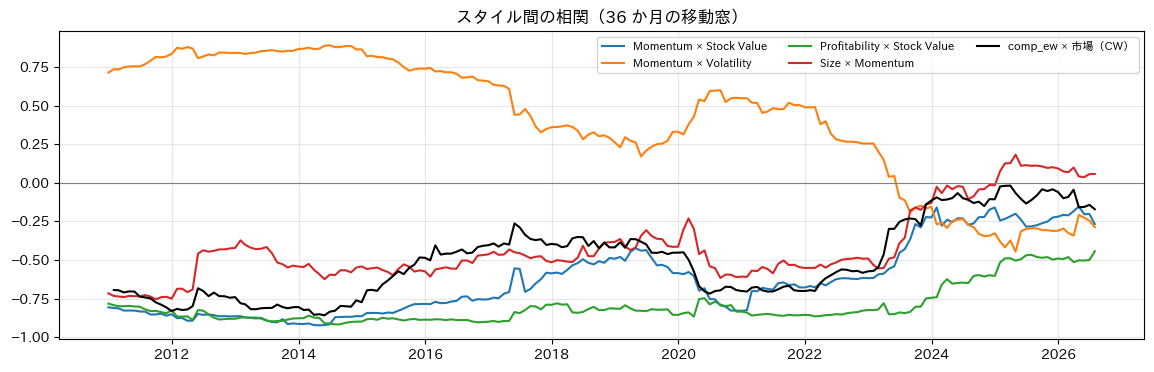

PC1 の説明力（36M 窓の終点の期間別平均）: {'2011–13': 0.49, '2014–17': 0.51, '2018–21': 0.43, '2022–26': 0.35}
         Momentum×Stock Value  Momentum×Volatility  Profitability×Stock Value  Size×Momentum  comp_ew×CW
2011–13                 -0.86                 0.82                      -0.85          -0.58       -0.77
2014–17                 -0.78                 0.71                      -0.88          -0.53       -0.56
2018–21                 -0.61                 0.40                      -0.82          -0.47       -0.54
2022–26                 -0.36                -0.11                      -0.67          -0.16       -0.25


In [6]:
X = G_full[core_names].loc["2009-01-31":]
X = X.loc[:, X.count() >= 150]
C = X.corr()
ev = np.linalg.eigvalsh(C.fillna(0).to_numpy())[::-1]
share = ev / ev.sum()
print(
    f"使ったファクター {X.shape[1]} 本。固有値の説明力: PC1 {share[0]:.1%}, PC1–3 {share[:3].sum():.1%}, PC1–5 {share[:5].sum():.1%}, PC1–10 {share[:10].sum():.1%}"
)

Xf = X.dropna(axis=1, thresh=int(len(X) * 0.95)).fillna(0)
evals, evecs = np.linalg.eigh(Xf.corr().to_numpy())
pc1 = pd.Series(evecs[:, -1], index=Xf.columns)
pc1 = pc1 * np.sign(pc1.sum())
print("PC1 の負荷量 上位:", pc1.sort_values().tail(8).round(2).to_dict())
print("PC1 の負荷量 下位:", pc1.sort_values().head(8).round(2).to_dict())

roll = {}
for i in range(36, len(Xf) + 1):
    w = Xf.iloc[i - 36 : i]
    e = np.linalg.eigvalsh(w.corr().fillna(0).to_numpy())
    roll[w.index[-1]] = e[-1] / e.sum()
roll = pd.Series(roll)

fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [1, 2]})
axes[0].bar(range(1, 16), share[:15])
axes[0].set_title("固有値の説明力（core、全期間）")
axes[1].plot(roll, color="k")
axes[1].set_title("第 1 主成分の説明力（36 か月の移動窓）")
plt.tight_layout()
plt.show()

pairs = [
    ("Momentum", "Stock Value"),
    ("Momentum", "Volatility"),
    ("Profitability", "Stock Value"),
    ("Size", "Momentum"),
]
fig, ax = plt.subplots(figsize=(14, 4))
for a, b in pairs:
    ax.plot(F[a].rolling(36).corr(F[b]), label=f"{a} × {b}")
ax.plot(
    F["comp_ew"].rolling(36).corr(cw),
    label="comp_ew × 市場（CW）",
    color="k",
    linewidth=1.5,
)
ax.axhline(0, color="gray", linewidth=0.8)
ax.legend(fontsize=8, ncol=3)
ax.set_title("スタイル間の相関（36 か月の移動窓）")
plt.show()
per = pd.cut(
    roll.index.year,
    [2010, 2014, 2018, 2022, 2027],
    right=False,
    labels=["2011–13", "2014–17", "2018–21", "2022–26"],
)
print(
    "PC1 の説明力（36M 窓の終点の期間別平均）:",
    roll.groupby(per, observed=False).mean().round(2).to_dict(),
)
rc = pd.DataFrame({f"{a}×{b}": F[a].rolling(36).corr(F[b]) for a, b in pairs})
rc["comp_ew×CW"] = F["comp_ew"].rolling(36).corr(cw)
print(
    rc.groupby(
        pd.cut(
            rc.index.year,
            [2010, 2014, 2018, 2022, 2027],
            right=False,
            labels=["2011–13", "2014–17", "2018–21", "2022–26"],
        ),
        observed=False,
    )
    .mean()
    .round(2)
)

## 3. 時系列の予測可能性（H1 ファクターモメンタム）

### 3.1 自己相関

各ファクター（130 本）の 1 次の自己相関と、ラグ 1〜12 の平均。帰無仮説（自己相関 0）の下での標準誤差はおよそ $1/\sqrt{T}\approx0.067$（ラグ 1〜12 の平均は約 0.019）。

130 本の AC1: 平均 0.056  中央値 0.054  正の割合 0.79  AC1 > 0.134（約 2σ）の本数 17
AC1–12 平均: 平均 0.004  正の割合 0.48


,AC1,AC1–12 平均,AC12,T
comp_ew,0.015,-0.025,-0.084,222.0
sleeve_a,0.054,0.015,0.040,222.0
sleeve_b,0.055,0.005,-0.052,222.0
sleeve_d,0.095,0.036,-0.045,222.0
Stock Value,0.051,0.009,-0.017,223.0
Flow Value,0.090,0.034,-0.009,223.0
Profitability,0.046,-0.005,-0.022,223.0
Growth,0.234,0.018,-0.043,223.0
Shareholder Return,0.106,0.007,-0.048,223.0
Momentum,0.046,0.007,-0.026,223.0


,AC1,AC1–12 平均,AC12,T
eiss,0.244,0.141,0.088,223.0
gpy,0.236,0.018,-0.185,222.0
Growth,0.234,0.018,-0.043,223.0
dp_act,0.208,0.049,0.027,223.0
csi,0.196,-0.002,-0.065,223.0
dp_est,0.195,0.082,0.005,223.0
dlt_roa_5y,0.192,-0.006,-0.053,223.0
oi_grw,0.170,0.021,-0.110,223.0


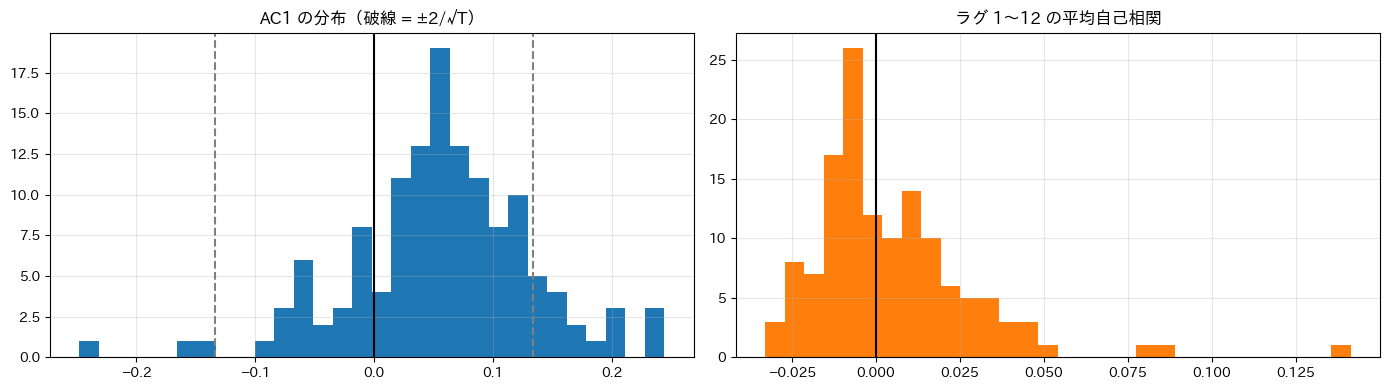

In [7]:
def autocorr_table(F: pd.DataFrame) -> pd.DataFrame:
    out = {}
    for n in F:
        x = F[n].dropna()
        ac = [x.autocorr(k) for k in range(1, 13)]
        out[n] = {"AC1": ac[0], "AC1–12 平均": np.mean(ac), "AC12": ac[11], "T": len(x)}
    return pd.DataFrame(out).T


ac = autocorr_table(F)
print(
    "130 本の AC1: 平均",
    round(ac["AC1"].mean(), 3),
    " 中央値",
    round(ac["AC1"].median(), 3),
    " 正の割合",
    round((ac["AC1"] > 0).mean(), 2),
    " AC1 > 0.134（約 2σ）の本数",
    int((ac["AC1"] > 0.134).sum()),
)
print(
    "AC1–12 平均: 平均",
    round(ac["AC1–12 平均"].mean(), 3),
    " 正の割合",
    round((ac["AC1–12 平均"] > 0).mean(), 2),
)
display(ac.loc[["comp_ew", "sleeve_a", "sleeve_b", "sleeve_d", *STYLES]].round(3))
display(ac.sort_values("AC1", ascending=False).head(8).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(ac["AC1"], bins=30, color="C0")
axes[0].axvline(0, color="k")
for s in (-2, 2):
    axes[0].axvline(s / np.sqrt(len(F)), color="gray", linestyle="--")
axes[0].set_title("AC1 の分布（破線 = ±2/√T）")
axes[1].hist(ac["AC1–12 平均"], bins=30, color="C1")
axes[1].axvline(0, color="k")
axes[1].set_title("ラグ 1〜12 の平均自己相関")
plt.tight_layout()
plt.show()

### 3.2 ファクターモメンタムの合成

各リターン月 $t+1$ について、$t$ までの情報だけで重みを決めて、ファクターを等ウェイトで合成する。

| 合成 | 重み $w_{f,t}$ |
| --- | --- |
| 静的（基準） | 拡大窓平均の符号 $\mathrm{sign}(\bar f_{\le t})$ |
| TS12 | 過去 12 か月合計の符号 $\mathrm{sign}(\sum_{s=t-11}^{t} f_s)$ |
| TS1 | 前月の符号 $\mathrm{sign}(f_t)$ |
| GK12 | Gupta–Kelly: 過去 12 か月合計 / (過去 36 か月の月次ボラ × √12)、±2 で打ち切り |
| CS 上位 / 下位 | 向き調整（拡大窓の符号）後の過去 12 か月で上位半分 / 下位半分を等ウェイトでロング |

ファクター集合は (a) `core` 全 123 本、(b) `core` から価格モメンタム（`mom*`）を除いた 119 本、(c) スタイル 9 本。
TS の合成は向きに依存しない（向きを反転すると符号も反転する）ので、ルックアヘッドは入らない。

年率      t   シャープ  IS 年率   IS t  OOS 年率  OOS t
core 123     静的          0.030  3.537  0.794  0.040  3.591   0.020  1.651
             TS12        0.032  2.139  0.541  0.034  1.381   0.031  1.701
             TS1         0.016  1.206  0.287  0.031  1.610   0.002  0.131
             GK12        0.032  1.759  0.413  0.035  1.231   0.029  1.261
             CS 上位       0.053  2.719  0.662  0.056  1.856   0.050  2.006
             CS 下位       0.006  0.412  0.109  0.024  1.008  -0.011 -0.834
             TS12 − 静的   0.002  0.190  0.049 -0.006 -0.275   0.010  0.761
             CS 上位 − 下位  0.047  1.625  0.423  0.032  0.642   0.062  1.931
core（mom 除く） 静的          0.031  3.523  0.807  0.046  3.708   0.018  1.471
             TS12        0.033  2.199  0.559  0.036  1.455   0.030  1.703
             TS1         0.016  1.234  0.294  0.032  1.697   0.002  0.097
             GK12        0.033  1.837  0.432  0.037  1.333   0.029  1.266
             CS 上位       0.054  2.753  0.674  0.060  1.963   0.048  1.944
             CS 下位       0.008  0.559  0.151  0.031  1.319  -0.014 -0.973
             TS12 − 静的   0.001  0.117  0.031 -0.010 -0.468   0.012  0.886
             CS 上位 − 下位  0.046  1.616  0.424  0.030  0.609   0.062  1.936
スタイル 9       静的          0.038  2.501  0.581  0.046  2.249   0.030  1.362
             TS12        0.038  1.538  0.380  0.049  1.176   0.028  0.994
             TS1         0.026  1.103  0.262  0.065  1.914  -0.011 -0.358
             GK12        0.040  1.414  0.313  0.055  1.188   0.026  0.780
             CS 上位       0.065  2.274  0.544  0.082  1.840   0.050  1.364
             CS 下位       0.003  0.130  0.032  0.002  0.046   0.004  0.182
             TS12 − 静的   0.000  0.013  0.003  0.003  0.074  -0.002 -0.103
             CS 上位 − 下位  0.063  1.501  0.368  0.080  1.081   0.047  1.087

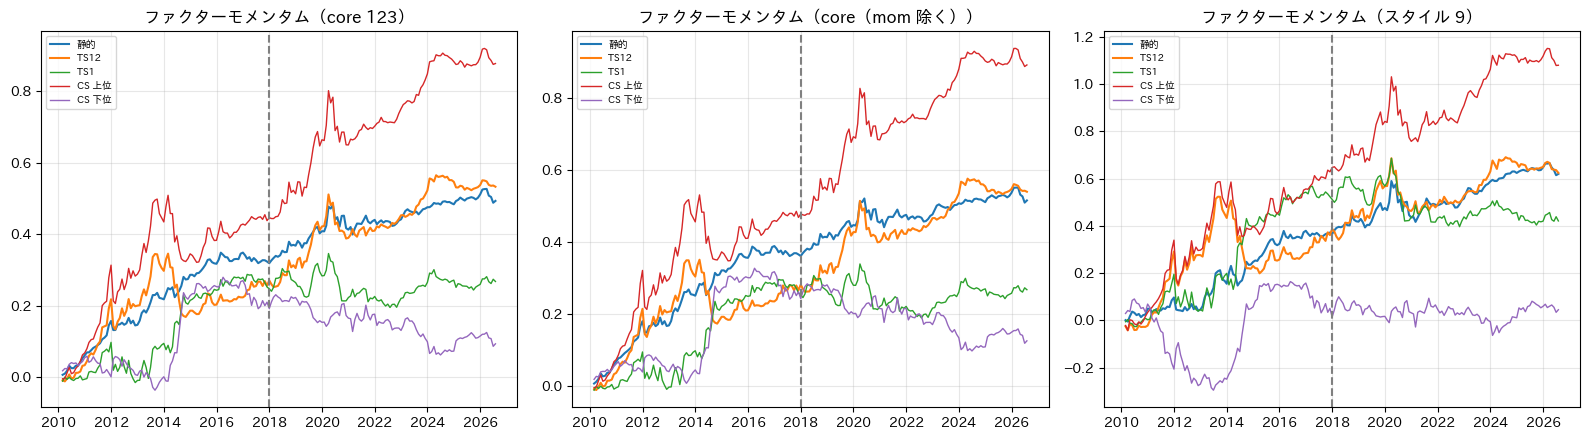

In [8]:
def fm_composites(F: pd.DataFrame) -> pd.DataFrame:
    sgn = np.sign(F.expanding(min_periods=24).mean()).shift(1)
    past12 = F.rolling(12, min_periods=12).sum().shift(1)
    vol36 = F.rolling(36, min_periods=24).std().shift(1) * np.sqrt(12)
    G = sgn * F
    gpast = sgn * past12
    rk = gpast.rank(axis=1, pct=True)
    out = {
        "静的": G.mean(axis=1),
        "TS12": (np.sign(past12) * F).mean(axis=1),
        "TS1": (np.sign(F.shift(1)) * F).mean(axis=1),
        "GK12": ((past12 / vol36).clip(-2, 2) * F).mean(axis=1),
        "CS 上位": G.where(rk > 0.5).mean(axis=1),
        "CS 下位": G.where(rk <= 0.5).mean(axis=1),
    }
    out = pd.DataFrame(out).loc[EVAL_START:]
    out["TS12 − 静的"] = out["TS12"] - out["静的"]
    out["CS 上位 − 下位"] = out["CS 上位"] - out["CS 下位"]
    return out


sets = {
    "core 123": core_names,
    "core（mom 除く）": [n for n in core_names if not n.startswith("mom")],
    "スタイル 9": STYLES,
}
fm = {k: fm_composites(F[v]) for k, v in sets.items()}
rows = {}
for k, df in fm.items():
    for c in df:
        rows[(k, c)] = perf_split(df[c])
display(pd.DataFrame(rows).T.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (k, df) in zip(axes, fm.items()):
    for c in ["静的", "TS12", "TS1", "CS 上位", "CS 下位"]:
        ax.plot(
            df[c].fillna(0).cumsum(),
            label=c,
            linewidth=1.5 if c in ("静的", "TS12") else 1,
        )
    ax.axvline(IS_END, color="gray", linestyle="--")
    ax.set_title(f"ファクターモメンタム（{k}）")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

### 3.3 ファクターモメンタムは銘柄モメンタムで説明できるか

TS12（`core` 全体 / `mom` 除く）を、`mom12_1` の Q5−Q1 と静的合成に回帰する（NW t 値、ラグ 3）。切片が残れば銘柄モメンタムとは別の情報。

In [9]:
mom = F["mom12_1"].rename("mom12_1")
for k in ["core 123", "core（mom 除く）", "スタイル 9"]:
    y = fm[k]["TS12"]
    res = ols_nw(y, pd.concat([mom, fm[k]["静的"].rename("静的")], axis=1).loc[y.index])
    res.loc["const", "coef"] *= 12
    print(f"--- {k}: TS12 = a + b·mom12_1 + c·静的（a は年率）  n={res.attrs['n']}")
    display(res.round(3).T)
    r2 = y.corr(mom.loc[y.index])
    print(f"    TS12 と mom12_1 の相関 {r2:.2f}")

--- core 123: TS12 = a + b·mom12_1 + c·静的（a は年率）  n=198


,const,mom12_1,静的
coef,-0.002,0.168,0.407
t,-0.184,6.612,2.314


    TS12 と mom12_1 の相関 0.69
--- core（mom 除く）: TS12 = a + b·mom12_1 + c·静的（a は年率）  n=198


,const,mom12_1,静的
coef,-0.001,0.152,0.442
t,-0.102,5.990,2.679


    TS12 と mom12_1 の相関 0.67
--- スタイル 9: TS12 = a + b·mom12_1 + c·静的（a は年率）  n=198


,const,mom12_1,静的
coef,-0.015,0.245,0.554
t,-0.921,5.065,3.605


    TS12 と mom12_1 の相関 0.68


## 4. ボラティリティ・タイミング（H2）

Moreira–Muir: $f^{\sigma}_{t+1} = c\, f_{t+1} / \widehat{RV}_t$。$\widehat{RV}_t$ は月 $t$ の日次ロングショートの二乗和（10 営業日以上）。$c$ は管理後のボラが元と同じになるよう全期間で決める（シャープとアルファの t 値には影響しない）。
$1/\sigma$ でスケールする版（回転率が穏やか）も見る。アルファは $f^{\sigma}$ を $f$ に回帰した切片（年率、NW t）。向きは全期間平均の符号で揃える。

[1/RV] 132 本: アルファ>0 の割合 0.63、アルファ t>2 の本数 15、t<−2 2、シャープの変化 中央値 -0.040
[1/σ] 132 本: アルファ>0 の割合 0.64、アルファ t>2 の本数 13、t<−2 4、シャープの変化 中央値 +0.006


,元のシャープ,管理後のシャープ,アルファ（年率）,アルファ t,OOS アルファ t,β
comp_ew,1.101,1.332,0.094,3.070,1.362,0.688
sleeve_a,1.323,1.414,0.040,2.218,0.841,0.784
sleeve_b,0.480,0.906,0.106,3.047,1.373,0.700
sleeve_d,1.115,1.009,0.015,0.918,1.071,0.781
mom12_1,0.302,0.754,0.132,2.744,1.317,0.648
mom1,0.124,-0.126,-0.036,-1.605,-0.734,0.738
Stock Value,0.124,0.143,0.011,0.326,1.529,0.732
Flow Value,0.734,0.630,0.011,0.647,1.297,0.756
Profitability,0.148,-0.069,-0.033,-1.312,-1.432,0.811
Growth,0.488,0.621,0.028,1.561,1.921,0.736


,元のシャープ,管理後のシャープ,アルファ（年率）,アルファ t,OOS アルファ t,β
comp_ew,1.101,1.407,0.068,3.153,1.673,0.897
sleeve_b,0.480,0.816,0.072,2.905,1.466,0.888
mom12_1,0.302,0.653,0.092,2.725,1.588,0.868
Momentum,0.631,0.923,0.062,3.004,1.741,0.927


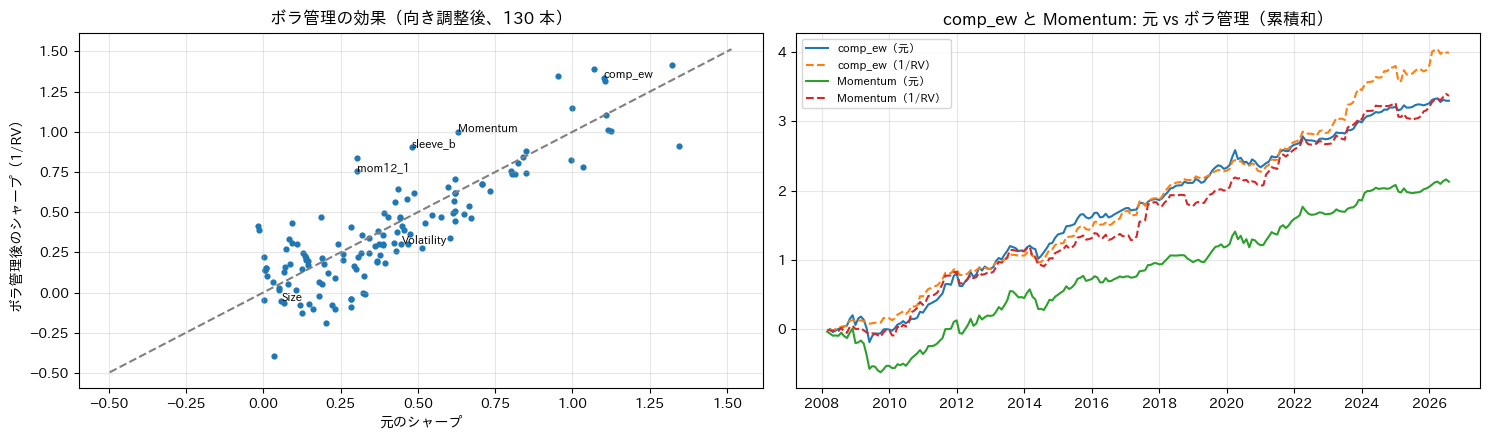

In [10]:
def month_label(idx: pd.DatetimeIndex) -> pd.DatetimeIndex:
    return idx.to_period("M").to_timestamp(how="end").normalize()


g = D.groupby(month_label(D.index))
RV = (D.pow(2)).groupby(month_label(D.index)).sum().where(g.count() >= MIN_DAYS)
RV = RV.reindex(F.index)


def vol_managed(f: pd.Series, rv: pd.Series, power: float) -> dict:
    w = 1.0 / rv.shift(1) ** power
    m = (f * w).dropna()
    f0 = f.loc[m.index]
    m = m * f0.std() / m.std()
    res = ols_nw(m, f0.rename("f").to_frame())
    oos = m.loc[IS_END + pd.Timedelta(days=1) :]
    res_o = ols_nw(oos, f0.loc[oos.index].rename("f").to_frame())
    return {
        "元のシャープ": f0.mean() / f0.std() * np.sqrt(12),
        "管理後のシャープ": m.mean() / m.std() * np.sqrt(12),
        "アルファ（年率）": res.loc["const", "coef"] * 12,
        "アルファ t": res.loc["const", "t"],
        "OOS アルファ t": res_o.loc["const", "t"],
        "β": res.loc["f", "coef"],
    }


Gd = F * dir_full
vm = {
    p: pd.DataFrame(
        {n: vol_managed(Gd[n], RV[n], p) for n in F if RV[n].notna().sum() > 100}
    ).T
    for p in (1.0, 0.5)
}
for p, t in vm.items():
    lab = "1/RV" if p == 1.0 else "1/σ"
    print(
        f"[{lab}] {len(t)} 本: アルファ>0 の割合 {(t['アルファ（年率）'] > 0).mean():.2f}、アルファ t>2 の本数 {(t['アルファ t'] > 2).sum()}、t<−2 {(t['アルファ t'] < -2).sum()}、"
        f"シャープの変化 中央値 {(t['管理後のシャープ'] - t['元のシャープ']).median():+.3f}"
    )
display(
    vm[1.0]
    .loc[["comp_ew", "sleeve_a", "sleeve_b", "sleeve_d", "mom12_1", "mom1", *STYLES]]
    .round(3)
)
display(vm[0.5].loc[["comp_ew", "sleeve_b", "mom12_1", "Momentum"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
t = vm[1.0]
axes[0].scatter(t["元のシャープ"], t["管理後のシャープ"], s=12)
for n in ["comp_ew", "sleeve_b", "mom12_1", "Momentum", "Volatility", "Size"]:
    axes[0].annotate(
        n, (t.loc[n, "元のシャープ"], t.loc[n, "管理後のシャープ"]), fontsize=8
    )
lim = [
    t[["元のシャープ", "管理後のシャープ"]].min().min() - 0.1,
    t[["元のシャープ", "管理後のシャープ"]].max().max() + 0.1,
]
axes[0].plot(lim, lim, color="gray", linestyle="--")
axes[0].set_xlabel("元のシャープ")
axes[0].set_ylabel("ボラ管理後のシャープ（1/RV）")
axes[0].set_title("ボラ管理の効果（向き調整後、130 本）")
for n in ["comp_ew", "Momentum"]:
    w = 1.0 / RV[n].shift(1)
    m = (Gd[n] * w).dropna()
    m = m * Gd[n].loc[m.index].std() / m.std()
    axes[1].plot(Gd[n].loc[m.index].cumsum(), label=f"{n}（元）")
    axes[1].plot(m.cumsum(), label=f"{n}（1/RV）", linestyle="--")
axes[1].legend(fontsize=8)
axes[1].set_title("comp_ew と Momentum: 元 vs ボラ管理（累積和）")
plt.tight_layout()
plt.show()

### 4.1 頑健性: ルックアヘッドの無いスケールと上限

上の $c$ は全期間で決めていた。実運用に近い形として、重み $w_t = (1/\widehat{RV}_t) / \mathrm{median}_{s\le t}(1/\widehat{RV}_s)$（自身の過去の中央値で基準化）を使い、
上限・下限 $[0.5, 2]$ を付けた版も比べる。`comp_ew` はロングオンリーに近い Q5−ユニバース EW でも見る。シャープは同じ月（2010-02 以降）で比べる。

In [11]:
def managed(
    f: pd.Series, rv: pd.Series, power: float, clip: tuple | None
) -> tuple[pd.Series, pd.Series]:
    inv = 1.0 / rv.shift(1) ** power
    w = inv / inv.expanding(24).median()
    if clip is not None:
        w = w.clip(*clip)
    return f * w, w


def sharpe(x: pd.Series) -> float:
    x = x.dropna()
    return x.mean() / x.std() * np.sqrt(12)


targets = {
    "comp_ew Q5−Q1": (F["comp_ew"], RV["comp_ew"]),
    "comp_ew Q5−EW": (Q5X["comp_ew"], RV["comp_ew"]),
    "sleeve_b Q5−Q1": (F["sleeve_b"], RV["sleeve_b"]),
    "Momentum Q5−Q1": (F["Momentum"], RV["Momentum"]),
    "sleeve_a Q5−Q1": (F["sleeve_a"], RV["sleeve_a"]),
}
variants = {
    "1/RV": (1.0, None),
    "1/RV [0.5,2]": (1.0, (0.5, 2.0)),
    "1/σ [0.5,2]": (0.5, (0.5, 2.0)),
}
EXCL = F.index[(F.index.year == 2009) | (F.index.year == 2020)]
rows = {}
for tn, (f, rv) in targets.items():
    for vn, (pw, cl) in variants.items():
        m, w = managed(f, rv, pw, cl)
        m = m.loc[EVAL_START:].dropna()
        f0 = f.loc[m.index]
        r = ols_nw(m, f0.rename("f").to_frame())
        is_, oos = m.index <= IS_END, m.index > IS_END
        ex = ~m.index.isin(EXCL)
        rows[(tn, vn)] = {
            "元 SR": sharpe(f0), "管理後 SR": sharpe(m), "アルファ t": r.loc["const", "t"],
            "IS 元": sharpe(f0[is_]), "IS 管理": sharpe(m[is_]), "OOS 元": sharpe(f0[oos]), "OOS 管理": sharpe(m[oos]),
            "2009・2020 除く 元": sharpe(f0[ex]), "除く 管理": sharpe(m[ex]),
            "w 平均": w.loc[m.index].mean(), "w の月次変化": w.loc[m.index].diff().abs().mean(),
        }  # fmt: skip
display(pd.DataFrame(rows).T.round(2))

元 SR  管理後 SR  アルファ t  IS 元  IS 管理  OOS 元  OOS 管理  2009・2020 除く 元  除く 管理  w 平均  w の月次変化
comp_ew Q5−Q1  1/RV          1.35    1.42    2.43  1.42   1.47   1.30    1.37            1.53   1.53  1.64     0.89
               1/RV [0.5,2]  1.35    1.57    3.40  1.42   1.58   1.30    1.55            1.53   1.72  1.36     0.43
               1/σ [0.5,2]   1.35    1.51    2.91  1.42   1.51   1.30    1.51            1.53   1.66  1.20     0.31
comp_ew Q5−EW  1/RV          1.62    1.52    1.66  1.81   1.92   1.43    1.31            1.74   1.58  1.64     0.89
               1/RV [0.5,2]  1.62    1.75    3.01  1.81   2.05   1.43    1.53            1.74   1.86  1.36     0.43
               1/σ [0.5,2]   1.62    1.73    2.59  1.81   1.97   1.43    1.52            1.74   1.83  1.20     0.31
sleeve_b Q5−Q1 1/RV          0.82    0.96    2.10  0.61   0.71   1.07    1.20            1.00   1.08  1.56     0.82
               1/RV [0.5,2]  0.82    0.99    2.13  0.61   0.73   1.07    1.23            1.00   1.15  1.32     0.42
               1/σ [0.5,2]   0.82    0.95    2.07  0.61   0.70   1.07    1.21            1.00   1.11  1.18     0.31
Momentum Q5−Q1 1/RV          0.98    1.11    2.21  1.04   1.15   0.92    1.08            1.11   1.15  1.41     0.81
               1/RV [0.5,2]  0.98    1.12    1.94  1.04   1.10   0.92    1.15            1.11   1.16  1.23     0.49
               1/σ [0.5,2]   0.98    1.11    2.25  1.04   1.14   0.92    1.08            1.11   1.18  1.12     0.34
sleeve_a Q5−Q1 1/RV          1.56    1.52    1.44  1.82   1.77   1.30    1.27            1.67   1.55  1.53     0.77
               1/RV [0.5,2]  1.56    1.68    2.42  1.82   1.92   1.30    1.45            1.67   1.74  1.35     0.46
               1/σ [0.5,2]   1.56    1.64    1.71  1.82   1.89   1.30    1.38            1.67   1.69  1.19     0.31

### 4.2 ボラは翌月のリターンを予測するか

ボラ管理が効くには「ボラが上がっても期待リターンが比例して上がらない」ことが要る。ファクターの翌月リターンを前月の実現ボラ（拡大窓で標準化）に回帰した傾きを、全ファクター（向き調整後）でプールして見る。

In [12]:
rows = []
for n in F:
    rv = RV[n]
    if rv.notna().sum() < 100:
        continue
    z = np.log(rv)
    z = ((z - z.expanding(24).mean()) / z.expanding(24).std()).shift(1)
    df = pd.concat([Gd[n].rename("f"), z.rename("z")], axis=1).dropna()
    rows.append(df.assign(factor=n))
pool = pd.concat(rows)
pool_m = pool.groupby(level=0).apply(
    lambda d: np.polyfit(d["z"], d["f"], 1)[0] if len(d) > 10 else np.nan
)
print(
    f"月ごとの横断回帰の傾き（f 〜 前月ボラの z）の平均: {pool_m.mean() * 100:.3f}%/σ、NW t {nw_t(pool_m):.2f}"
)
for n in ["comp_ew", "Momentum", "sleeve_b", "mom12_1"]:
    d = pool[pool["factor"] == n]
    r = ols_nw(d["f"], d[["z"]])
    print(f"  {n}: 傾き {r.loc['z', 'coef'] * 100:+.3f}%/σ (t {r.loc['z', 't']:.2f})")

月ごとの横断回帰の傾き（f 〜 前月ボラの z）の平均: 0.111%/σ、NW t 1.63
  comp_ew: 傾き -0.478%/σ (t -1.50)
  Momentum: 傾き -0.522%/σ (t -1.82)
  sleeve_b: 傾き -0.352%/σ (t -0.85)
  mom12_1: 傾き -0.452%/σ (t -1.15)


## 5. ファクターの割安度（H3、価値スプレッド）

月末 $t$ に、各ファクターの Q5 と Q1 の BP（$1/\mathrm{PBR}$）の中央値の比のログ $v_t=\log(\mathrm{BP}_{Q5}/\mathrm{BP}_{Q1})$ を計算する。
$z_t$ は $t$ までの拡大窓（最低 36 か月）で標準化した値。$z_t$ が高い = ロング側が過去と比べて割安。翌 1 か月と翌 12 か月（重複、NW ラグ 12）のファクターリターンに回帰する。
傾きの符号はファクターの向きに依存しない（向きを反転すると $v$ もリターンも反転する）。

,1M 傾き(%/σ),1M t,12M 傾き(%/σ),12M t,IS 1M t,OOS 1M t,z の現在値
Stock Value,0.06,0.12,2.17,0.45,-0.18,1.29,-0.44
Flow Value,0.10,0.28,4.30,1.24,0.10,0.01,-0.21
Profitability,-0.21,-0.50,-3.07,-1.14,-0.68,0.99,-0.15
Growth,-0.19,-0.99,1.08,0.56,-1.10,-0.21,-0.53
Shareholder Return,-0.58,-2.81,-5.10,-3.53,-2.36,-0.60,0.52
Momentum,0.38,1.11,3.05,1.42,0.05,2.94,0.13
Volatility,-0.73,-1.60,-6.42,-2.51,-1.29,-0.51,1.14
Financial Quality,-0.30,-0.90,-2.85,-1.22,-1.08,0.01,0.42
Size,0.30,1.08,3.33,1.23,0.00,2.83,-0.90
comp_ew,0.08,0.31,0.23,0.14,-0.37,1.86,0.13


プール（20 本、月ごとの横断傾きの平均）: 0.101%/σ、NW t 0.56


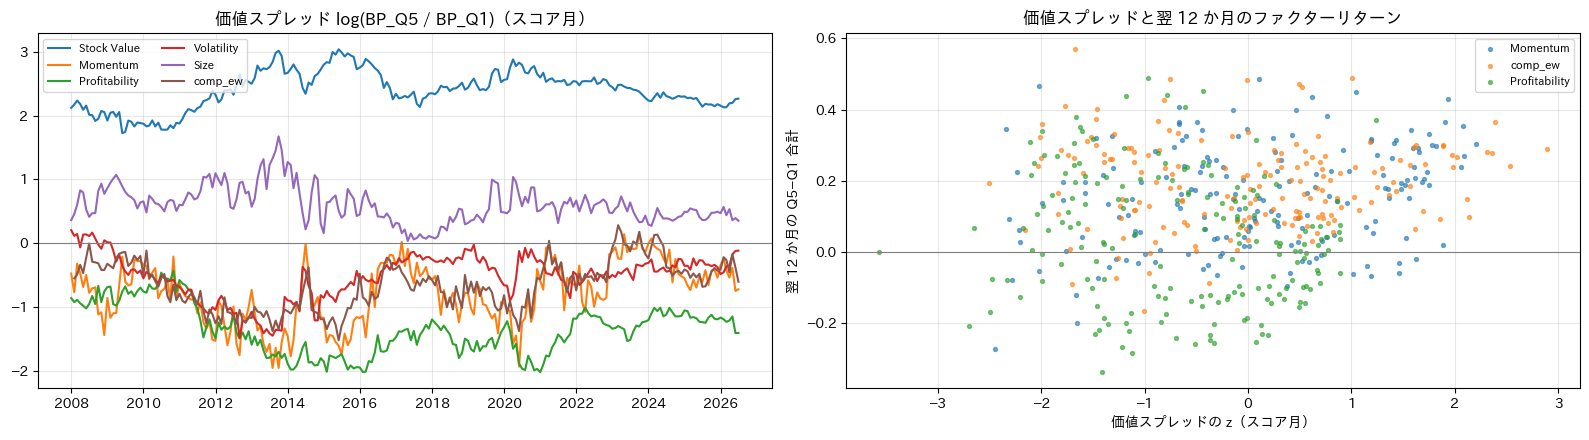

In [13]:
VS_SET = [
    *STYLES,
    "comp_ew",
    "sleeve_a",
    "sleeve_b",
    "sleeve_d",
    "mom12_1",
    "mom1",
    "vola60",
    "roe_act",
    "ep_act",
    "ta_grw",
    "mv",
]
z = (VS - VS.expanding(36).mean()) / VS.expanding(36).std()
z_ret = z.copy()
z_ret.index = z_ret.index + pd.offsets.MonthEnd(
    1
)  # スコア月 t → 予測するリターン月 t+1
F12 = (
    F[::-1].rolling(12, min_periods=12).sum()[::-1]
)  # t..t+11 の合計（リターン月 t から先の 12 か月）
rows = {}
for n in VS_SET:
    zz = z_ret[n].reindex(F.index).rename("z")
    r1 = ols_nw(F[n], zz.to_frame())
    r12 = ols_nw(F12[n], zz.to_frame(), lags=12)
    ris = ols_nw(F[n].loc[:IS_END], zz.loc[:IS_END].to_frame())
    roos = ols_nw(
        F[n].loc[IS_END + pd.Timedelta(days=1) :],
        zz.loc[IS_END + pd.Timedelta(days=1) :].to_frame(),
    )
    rows[n] = {
        "1M 傾き(%/σ)": r1.loc["z", "coef"] * 100, "1M t": r1.loc["z", "t"],
        "12M 傾き(%/σ)": r12.loc["z", "coef"] * 100, "12M t": r12.loc["z", "t"],
        "IS 1M t": ris.loc["z", "t"], "OOS 1M t": roos.loc["z", "t"], "z の現在値": z[n].dropna().iloc[-1],
    }  # fmt: skip
vs_tbl = pd.DataFrame(rows).T
display(vs_tbl.round(2))
pooled = []
for n in VS_SET:
    pooled.append(
        pd.concat([F[n].rename("f"), z_ret[n].reindex(F.index).rename("z")], axis=1)
        .dropna()
        .assign(factor=n)
    )
pooled = pd.concat(pooled)
sl = pooled.groupby(level=0).apply(
    lambda d: np.polyfit(d["z"], d["f"], 1)[0] if len(d) > 5 else np.nan
)
print(
    f"プール（{len(VS_SET)} 本、月ごとの横断傾きの平均）: {sl.mean() * 100:.3f}%/σ、NW t {nw_t(sl):.2f}"
)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for n in ["Stock Value", "Momentum", "Profitability", "Volatility", "Size", "comp_ew"]:
    axes[0].plot(VS[n], label=n)
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].legend(fontsize=8, ncol=2)
axes[0].set_title("価値スプレッド log(BP_Q5 / BP_Q1)（スコア月）")
for n in ["Momentum", "comp_ew", "Profitability"]:
    d = pd.concat(
        [z_ret[n].reindex(F.index).rename("z"), F12[n].rename("f12")], axis=1
    ).dropna()
    axes[1].scatter(d["z"], d["f12"], s=8, label=n, alpha=0.6)
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_xlabel("価値スプレッドの z（スコア月）")
axes[1].set_ylabel("翌 12 か月の Q5−Q1 合計")
axes[1].legend(fontsize=8)
axes[1].set_title("価値スプレッドと翌 12 か月のファクターリターン")
plt.tight_layout()
plt.show()

## 6. 市場との関係（H4）

### 6.1 同時相関と上方・下方ベータ

$f_t = a + \beta^{+}\max(m_t,0) + \beta^{-}\min(m_t,0) + \varepsilon_t$（$m_t$ = MSCI India IMI プロキシの時価総額加重 `cw_imi`）。
$\beta^{-}>\beta^{+}$ なら「下落で負け、上昇で勝つ」、$\beta^{-}<\beta^{+}$ ならその逆（$\beta^{-}$ が負なら下落月に勝つ）。EW−CW（中小型の相対）との相関も。

,向き,相関 CW,相関 EW−CW,β+,t(β+),β−,t(β−),β+ − β− の差
comp_ew,1.0,-0.583,-0.539,-0.703,-9.799,-0.167,-2.276,-0.537
sleeve_a,1.0,-0.407,-0.414,-0.383,-7.599,-0.008,-0.151,-0.374
sleeve_b,1.0,-0.481,-0.528,-0.816,-6.405,0.015,0.211,-0.831
sleeve_d,1.0,-0.608,-0.518,-0.281,-4.435,-0.337,-5.846,0.056
Stock Value,1.0,0.552,0.683,0.920,9.090,0.165,1.914,0.755
Flow Value,1.0,0.440,0.588,0.554,8.170,0.031,0.381,0.523
Profitability,1.0,-0.508,-0.634,-0.550,-5.205,-0.275,-2.257,-0.274
Growth,1.0,0.228,0.184,0.090,0.492,0.142,1.493,-0.051
Shareholder Return,1.0,-0.633,-0.642,-0.407,-7.352,-0.360,-4.706,-0.046
Momentum,1.0,-0.398,-0.473,-0.690,-7.883,0.030,0.330,-0.720


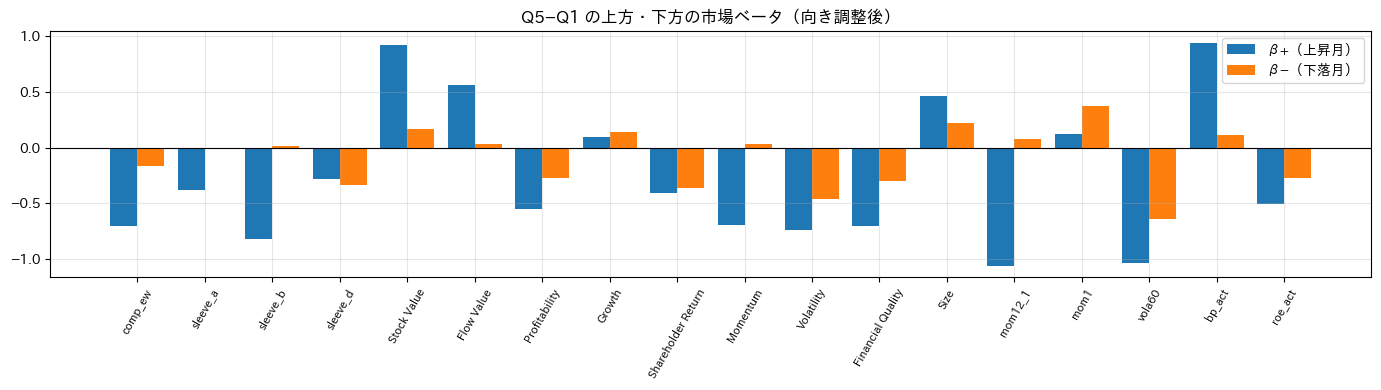

In [14]:
m = cw.reindex(F.index)
ud = pd.DataFrame({"up": m.clip(lower=0), "down": m.clip(upper=0)})
rows = {}
for n in [
    "comp_ew",
    "sleeve_a",
    "sleeve_b",
    "sleeve_d",
    *STYLES,
    "mom12_1",
    "mom1",
    "vola60",
    "bp_act",
    "roe_act",
]:
    f = F[n] * (dir_full[n] if n in core_names else 1)
    r = ols_nw(f, ud)
    rows[n] = {
        "向き": dir_full[n] if n in core_names else 1, "相関 CW": f.corr(m), "相関 EW−CW": f.corr(ew_cw.reindex(F.index)),
        "β+": r.loc["up", "coef"], "t(β+)": r.loc["up", "t"], "β−": r.loc["down", "coef"], "t(β−)": r.loc["down", "t"],
        "β+ − β− の差": r.loc["up", "coef"] - r.loc["down", "coef"],
    }  # fmt: skip
beta_tbl = pd.DataFrame(rows).T
display(beta_tbl.round(3))

fig, ax = plt.subplots(figsize=(14, 4))
x = np.arange(len(beta_tbl))
ax.bar(x - 0.2, beta_tbl["β+"], width=0.4, label="β+（上昇月）")
ax.bar(x + 0.2, beta_tbl["β−"], width=0.4, label="β−（下落月）")
ax.set_xticks(x, beta_tbl.index, rotation=60, fontsize=8)
ax.axhline(0, color="k", linewidth=0.8)
ax.legend()
ax.set_title("Q5−Q1 の上方・下方の市場ベータ（向き調整後）")
plt.tight_layout()
plt.show()

### 6.2 市場の急反発月

市場が大きく上がった月（`cw_imi` の上位 12 か月）と、そのうち過去 12 か月がマイナスだった「弱気後の反発」月での各ファクター。

In [15]:
past12m = np.log1p(cw).rolling(12).sum().shift(1).reindex(F.index)
top_m = m.sort_values().tail(12).index.sort_values()
cols = [
    "comp_ew",
    "sleeve_a",
    "sleeve_b",
    "sleeve_d",
    "Momentum",
    "Volatility",
    "Size",
    "Stock Value",
    "Profitability",
]
tb = F.loc[top_m, cols].copy()
tb.insert(0, "市場", m.loc[top_m])
tb.insert(1, "過去12M市場", past12m.loc[top_m])
tb.index = tb.index.strftime("%Y-%m")
display(tb.round(3))
reb = (m > m.quantile(0.8)) & (past12m < 0)
print(f"弱気後の反発月（市場が上位 20% かつ過去 12 か月 < 0）: {int(reb.sum())} か月")
print((F.loc[reb, cols].mean() * 100).round(2).to_string())
print("それ以外の月の平均（%）:")
print((F.loc[~reb, cols].mean() * 100).round(2).to_string())

,市場,過去12M市場,comp_ew,sleeve_a,sleeve_b,sleeve_d,Momentum,Volatility,Size,Stock Value,Profitability
2008-04,0.121,0.446,-0.042,0.011,-0.009,-0.041,-0.030,-0.078,0.024,0.049,-0.040
2009-03,0.108,-0.791,-0.047,-0.034,-0.035,-0.040,-0.046,0.020,-0.030,-0.025,0.055
2009-04,0.183,-0.546,-0.116,-0.051,-0.137,-0.053,-0.159,-0.119,0.090,0.136,-0.007
2009-05,0.320,-0.492,-0.206,-0.097,-0.326,-0.123,-0.205,-0.278,0.308,0.342,-0.206
2010-09,0.103,0.174,-0.005,0.036,-0.007,-0.005,0.033,0.001,-0.055,-0.034,-0.001
2011-03,0.091,0.048,0.017,0.000,0.014,0.041,-0.000,-0.007,-0.047,-0.009,0.014
2012-01,0.132,-0.318,-0.183,-0.109,-0.249,-0.051,-0.184,-0.194,0.020,0.195,-0.186
2016-03,0.098,-0.208,-0.065,-0.052,-0.034,-0.015,-0.072,-0.044,0.025,0.088,-0.039
2020-04,0.154,-0.305,-0.128,-0.062,-0.129,0.001,-0.111,-0.087,0.115,0.104,0.033
2020-11,0.093,0.030,-0.055,-0.011,-0.087,-0.038,-0.045,-0.004,0.048,0.130,-0.121


弱気後の反発月（市場が上位 20% かつ過去 12 か月 < 0）: 15 か月
comp_ew         -6.88
sleeve_a        -3.53
sleeve_b        -8.08
sleeve_d        -2.76
Momentum        -7.23
Volatility      -7.59
Size             4.81
Stock Value      8.73
Profitability   -4.75
それ以外の月の平均（%）:
comp_ew          2.09
sleeve_a         1.52
sleeve_b         1.37
sleeve_d         1.27
Momentum         1.53
Volatility       1.32
Size            -0.28
Stock Value     -0.38
Profitability    0.59


### 6.3 `comp_ew` 自身の時系列

`comp_ew` の翌月の Q5−Q1（とロングオンリーに近い Q5−ユニバース EW）を、月末 $t$ の情報に単回帰する（NW t、ラグ 3）。
説明変数: 自身の過去 1・12 か月、前月の実現ボラ（日次ロングショート）、市場の過去 12 か月（対数）、EW−CW の過去 12 か月、`comp_ew` の価値スプレッド z、ファクター全体の第 1 主成分の説明力（36 か月）。

傾き(%/σ)     t  IS t  OOS t      n
Q5−Q1 自身 過去1M          0.07  0.20  0.31  -0.28  221.0
      自身 過去12M        -0.40 -1.21 -0.58  -1.87  210.0
      自身 実現ボラ(前月)     -0.67 -1.87 -1.73  -1.36  221.0
      市場 過去12M         1.03  2.36  1.76   2.74  222.0
      EW−CW 過去12M      0.76  2.64  2.17   1.47  222.0
      価値スプレッド z        0.10  0.31 -0.37   1.86  187.0
      PC1 説明力(36M)     0.23  0.81  0.89   1.10  175.0
Q5−EW 自身 過去1M         -0.02 -0.16  0.04  -0.71  221.0
      自身 過去12M        -0.19 -1.29 -0.44  -2.39  210.0
      自身 実現ボラ(前月)     -0.24 -1.37 -1.22  -1.94  221.0
      市場 過去12M         0.36  1.67  0.98   3.85  222.0
      EW−CW 過去12M      0.28  2.10  1.38   1.97  222.0
      価値スプレッド z        0.08  0.56  0.30   2.15  187.0
      PC1 説明力(36M)     0.18  1.64  0.75   1.73  175.0

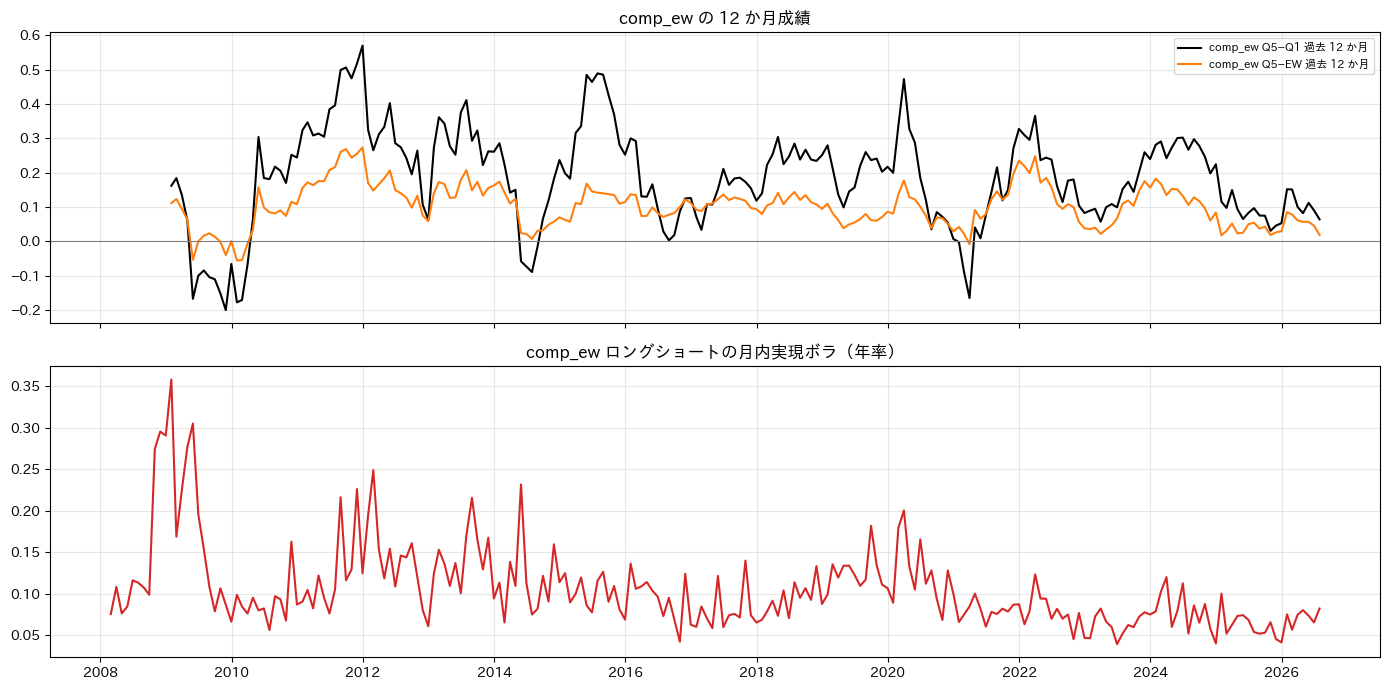

In [16]:
cf = F["comp_ew"]
preds = pd.DataFrame({
    "自身 過去1M": cf.shift(1),
    "自身 過去12M": cf.rolling(12).sum().shift(1),
    "自身 実現ボラ(前月)": np.sqrt(RV["comp_ew"]).shift(1),
    "市場 過去12M": past12m,
    "EW−CW 過去12M": ew_cw.rolling(12).sum().shift(1).reindex(F.index),
    "価値スプレッド z": z_ret["comp_ew"].reindex(F.index),
    "PC1 説明力(36M)": roll.shift(1).reindex(F.index),
}, index=F.index)  # fmt: skip
rows = {}
for tgt_name, tgt in [("Q5−Q1", cf), ("Q5−EW", Q5X["comp_ew"])]:
    for c in preds:
        x = preds[[c]]
        x = (x - x.mean()) / x.std()
        r = ols_nw(tgt, x)
        ri = ols_nw(tgt.loc[:IS_END], x.loc[:IS_END])
        ro = ols_nw(
            tgt.loc[IS_END + pd.Timedelta(days=1) :],
            x.loc[IS_END + pd.Timedelta(days=1) :],
        )
        rows[(tgt_name, c)] = {
            "傾き(%/σ)": r.loc[c, "coef"] * 100, "t": r.loc[c, "t"],
            "IS t": ri.loc[c, "t"], "OOS t": ro.loc[c, "t"], "n": r.attrs["n"],
        }  # fmt: skip
display(pd.DataFrame(rows).T.round(2))

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(cf.rolling(12).sum(), color="k", label="comp_ew Q5−Q1 過去 12 か月")
axes[0].plot(
    Q5X["comp_ew"].rolling(12).sum(), color="C1", label="comp_ew Q5−EW 過去 12 か月"
)
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].legend(fontsize=8)
axes[0].set_title("comp_ew の 12 か月成績")
axes[1].plot(np.sqrt(RV["comp_ew"] * 12), color="C3")
axes[1].set_title("comp_ew ロングショートの月内実現ボラ（年率）")
plt.tight_layout()
plt.show()

## 所見

**結論: ファクターの過去の成績（ファクターモメンタム）や割安度（価値スプレッド）を使って `comp_ew` の中身（スリーブやスタイルの配分）を動かす根拠は無い。唯一、IS・OOS・ロングオンリー近似のすべてで効いた時系列情報は、`comp_ew` 自身の直近のボラ。ボラが高い月の翌月にアクティブの賭けを小さくする（ボラ管理）と、シャープは 1.35 → 1.57 に上がる（アルファ t 3.4）。**

1. **基本統計**（Q5−Q1、drtn、2008-01〜2026-07）: `comp_ew` は年率 17.9%（t 5.2、シャープ 1.10、最大 DD −39%）。スリーブは a（リビジョン）14.1%（t 5.8）、d（規律）11.9%（t 4.4）、b（モメンタム + CGO）8.8%（t 2.1、最大 DD −64%）。
   スタイルでは Shareholder Return 11.1%（t 3.6）、Momentum 11.3%（t 2.7）、Flow Value 10.8%（t 2.8）が強く、Stock Value 2.8%、Profitability 2.7%、Size 0.7% は t < 1、Growth は −5.3%（t −1.7）。
   `core` 123 本は、向きを揃えると 35 本が t > 2 になる（向きは結果を見て決めているので楽観的）。OOS でも t > 2 なのは 7 本（`rev1r`、`rev3r`、`rev1p`、`rev3p`、`xfin_sp`、`noa_grw_fy`、`acc_bs`）で、37 本は IS と OOS で符号が反転する。最も頑健なのはリビジョン。
2. **ファクター間の相関構造**: 第 1 主成分が 41%（上位 3 つで 58%）を説明する。中身は「収益性・クオリティ（`roe`、`roic`、`gpa`）対 割安（`bp`、`tobin_q`、`mve_tl`）」の 1 本の軸で、インドの factor zoo は大部分が同じ賭け。
   ただし 36 か月の移動窓で見ると、第 1 主成分の説明力は 0.49〜0.51（2011〜17 年）から 0.35（2022〜26 年）に下がった。Momentum × Stock Value の相関は −0.86 → −0.36、Momentum × Volatility は +0.82 → −0.11、`comp_ew` × 市場は −0.77 → −0.25 と弱まっている。近年はファクターが「低ベータ・クオリティ」という一つの賭けに縮退しにくくなった。
3. **自己相関**: 1 次の自己相関（AC1）は 130 本の平均 0.056、79% が正で、17 本は約 2σ（0.134）を超える（Growth 0.23、`eiss` 0.24、`dp_act` 0.21）。ラグ 1〜12 の平均は 0.004（正は 48%）で、持続は 1 か月で消える。`comp_ew` の AC1 は 0.015。
4. **ファクターモメンタム（H1）は不成立**: `core` 123 本の TS12（過去 12 か月の符号）は年率 3.2%（t 2.1）で、静的な等ウェイト合成 3.0%（t 3.5）との差は +0.2%（t 0.2）。TS1 は t 1.2（OOS 0.1）。
   TS12 を `mom12_1` と静的合成に回帰すると、切片は −0.2%（t −0.2）で `mom12_1` の係数は t 6.6。`mom` 系を除いても、スタイル 9 本でも同じ。横断面（上位半分 − 下位半分）は 4.7%（t 1.6、IS 0.6 / OOS 1.9）。
   **インドのファクターモメンタムは「銘柄モメンタム + 静的プレミアム」で説明でき、それ以上の情報は無い**。`style_dtw` の mom12/mom3 ベースラインで上乗せが無かったことと整合する。
5. **ボラ・タイミング（H2）はモメンタム型にだけ効く**: 130 本全体では、1/RV でアルファの t > 2 が 15 本（t < −2 は 2 本）、シャープの変化の中央値は −0.04 で、一般則ではない。効くのは `comp_ew`（シャープ 1.10 → 1.33、アルファ 9.4%、t 3.1）、
   `sleeve_b`（0.48 → 0.91、t 3.0）、`mom12_1`（0.30 → 0.75、t 2.7）、Momentum スタイル（0.63 → 1.00、t 3.0）。バリュー、Profitability、Financial Quality、Size ではむしろ悪化する。
   - **頑健性（§4.1、自身の過去中央値で基準化、[0.5, 2] で打ち切り、2010-02 以降）**: `comp_ew` の Q5−Q1 は 1.35 → 1.57（アルファ t 3.4）。IS 1.42 → 1.58、OOS 1.30 → 1.55、2009・2020 年を除いても 1.53 → 1.72。
     ロングオンリーに近い Q5−EW でも 1.62 → 1.75（t 3.0）、OOS 1.43 → 1.53。重みの月次変化は平均 0.43（1/σ 版は 0.31）。打ち切らない 1/RV は Q5−EW で悪化する（1.62 → 1.52）ので、上限・下限は必要。
   - 仕組み（§4.2）: `comp_ew` の翌月リターンは前月ボラが高いほど低い（−0.48%/σ、t −1.5。Momentum −0.52%/σ、t −1.8）。全ファクターをプールすると傾きは +0.11%/σ（t 1.6）なので、「ボラが上がっても期待リターンが上がらない」のはクラッシュしやすいモメンタム型に限られる。
6. **ファクターの割安度（H3）は一般には不成立**: 20 本をプールした傾きは 0.10%/σ（t 0.6）。例外はモメンタム系で、`mom12_1`（12 か月 t 3.2、OOS 1 か月 t 3.1）と `sleeve_b`（12 か月 t 3.6）は正。勝ち組が負け組に比べて過去ほど割高でないとき、その後のモメンタムが強い（混雑度の指標として読める）。
   一方 Shareholder Return（t −2.8）と `sleeve_d`（t −2.9）は理論と逆符号。約 40 の検定の中の結果で、モメンタム系の 3 本も互いに独立ではないので、弱い証拠として扱う。
7. **市場との非対称（H4）は強く成立**: `comp_ew` の Q5−Q1 は上昇月のベータ $\beta^{+}=-0.70$（t −9.8）に対し、下落月は $\beta^{-}=-0.17$（t −2.3）。`mom12_1` は $\beta^{+}=-1.06$、$\beta^{-}=+0.08$、`sleeve_b` は −0.82 / +0.02 で、典型的な「コールの売り」型。
   バリュー（Stock Value $\beta^{+}=+0.92$）は逆。弱気後の反発月（市場が上位 20% かつ過去 12 か月がマイナス、15 か月）では、`comp_ew` は月平均 −6.9%（それ以外の月は +2.1%）。Momentum −7.2%、Volatility −7.6% に対し、Stock Value +8.7%、Size +4.8%。
   最大の負けは 2009-05（−20.6%）、2012-01（−18.3%）、2020-04（−12.8%）、2009-04（−11.6%）。
8. **`comp_ew` 自身の時系列（§6.3）**: 市場の過去 12 か月は正の予測力を持つ（+1.03%/σ、t 2.4、IS 1.8 / OOS 2.7。Q5−EW では OOS t 3.9）。EW−CW の過去 12 か月も正（t 2.6、IS 2.2 / OOS 1.5）。
   自身の過去 12 か月はむしろ負（t −1.2、OOS −1.9）で、`comp_ew` には持続性が無い。自身のボラは負（t −1.9）、価値スプレッドは効かない（t 0.3）。

**含意（`comp_ew` の重み付けを時系列情報で動かすべきか）**

- **中身（スリーブ・スタイルの配分）は、過去の成績や割安度では動かさない**。ファクターモメンタムは銘柄モメンタム（すでに `sleeve_b` に入っている）の言い換えで、割安度の予測力もモメンタム系以外では無い。`style_dtw`（DTW・mom12）の否定的な結果とも一致する。
- **動かす価値があるのは「量」**、つまりアクティブリスク（TE）の大きさ。`comp_ew` は「上昇相場の急反発で負けるコールの売り」の形をしている。反発はボラが高い局面で起きるので、自身の実現ボラでアクティブの賭けを縮めると、平均を大きく削らずに左裾を切れる。
  効果は IS・OOS の両方、2009・2020 年を除いても残り、Q5−EW でも出る。`momentum_regime` の `comp_hivol0`（市場ボラが高い月に `sleeve_b` を外す二値判定）が効かなかったのとは設計が違う。こちらは**ファクター自身の日次ロングショートのボラ**による**連続的なスケーリング**で、合成全体にかける。
- 市場の過去 12 か月（弱気判定）にも予測力はある（OOS t 2.7）。ただし `momentum_regime` で「中身を変える」使い方は失敗しているので、使うならボラ管理と同じく「量」に使う方が整合的。
- ファクター間の相関は近年弱まり（第 1 主成分 0.5 → 0.35）、`comp_ew` と市場の負の相関も −0.77 → −0.25 に緩んだ。ボラ管理の効果も 2010 年代前半ほど大きくない可能性があり、直近の期間で再確認が要る。

**次の候補（アイディア）**

1. **`comp_ew` のアクティブリスクのボラ管理**（本命）: bax の TE 目標（またはリスク回避度）を、`comp_ew` の日次 Q5−Q1 の前月実現分散の逆数（自身の過去中央値で基準化、[0.5, 2]）でスケールする。コストと税（スケールを縮めた月の売却で STCG が出る）を込めて評価する。
   市場の過去 12 か月（弱気判定）を説明変数に加えたときに上乗せが残るかも見る。
2. **スリーブ単位のボラ管理**: `sleeve_b`（アルファ t 2.1〜3.0）だけを 1/RV でスケールし、a・d（アルファ無し）は固定にする。リスク・パリティ型の時変スリーブ配分になる。過去の成績ではなくボラで中身を動かす唯一の候補。
3. **モメンタムの混雑度**: `mom12_1` / `sleeve_b` の価値スプレッドの z が低い（勝ち組が割高）ときに `sleeve_b` を軽くする。証拠は弱く、多重検定の中の結果なので優先度は低い。
4. **やらないもの**: ファクターモメンタム（TS・横断面）による合成の動的配分、モメンタム系以外の価値スプレッドによるタイミング。

**注意**

- ロングショートは等ウェイト・コスト控除前。ボラ管理の評価はスケールに依存しないシャープとアルファで行っており、TE を変えたときの実際の回転率・税は未評価。
- `availm12`、`availm60`、`intwo` は分位が作れない（値の同順位が多い、またはカバレッジ不足）ため除外。`mv` と `mv_usd` は同じ結果。
- データ: PBR ≤ 0 と PBR > 1000 を欠損として扱った（`build_market_panel.py` は −999999998 と ±10000 の張り付きを欠損にしている。ここではさらに負の簿価と極端値を除いた）。